# **🧩 Patch Clustering**

In this notebook, we investigate the localized semantic representations learned by Meta's **DINOv3** model. By clustering individual image patches based on their high-dimensional feature vectors, we aim to map out where specific visual features group together in the latent space. This localized analysis is a foundational step for our Hierarchical Out-of-Distribution (OOD) detection experiments.

### **⚙️ Experimental Pipeline**

1. **Feature Extraction:** Process the input images through the DINOv3 backbone to extract dense feature vectors for each constituent image patch.
2. **Unsupervised Clustering:** Group the extracted patch features using clustering algorithms (e.g., K-Means++) to identify distinct, recurring visual patterns across the dataset.
3. **Distribution Analysis:** Represent entire images as frequency histograms of their patch clusters and quantitatively compare these distributions using the **Chi-Square** distance metric.
4. **Semantic Mapping (Ideal Scenario):** Assign human-readable semantic labels (words) to the resulting clusters, effectively constructing a localized, interpretable visual dictionary.

## **0. Model preparation 🤖**

### **Imports**

In [8]:
import torch
import numpy as np
import torchvision
import matplotlib.pyplot as plt
import kagglehub
from transformers import AutoImageProcessor, AutoModel

### **Model Preparation**

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
from huggingface_hub import login
login()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [9]:
model_name = "facebook/dinov3-vit7b16-pretrain-lvd1689m"

print(f"Loading flagship model: {model_name}")
print(f"Targeting Architecture: 40 Layers, 4096 Embedding Dim")

if 'dtype' not in locals():
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32

try:
    #Load Model with Memory Optimization and Eager Attention
    # We strictly need eager attention to capture the attention weights
    model = AutoModel.from_pretrained(
        model_name,
        torch_dtype=dtype,
        low_cpu_mem_usage=True,
        attn_implementation="eager"
    ).to(device).eval()

    #Load Processor
    processor = AutoImageProcessor.from_pretrained(model_name)

    num_registers = getattr(model.config, "num_register_tokens", 4)
    print(f"Model loaded. Number of register tokens identified: {num_registers}")

    transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

    #Verify Layer Count
    if hasattr(model, "vision_model"):
        num_layers = len(model.vision_model.encoder.layers)
    else:
        #Fallback for flat architectures
        num_layers = len(model.layer)

    print(f"Success! Model loaded with {num_layers} layers.")

except Exception as e:
    print(f"Error loading model: {e}")
    print("Tip: If you run out of memory (OOM), try 'dinov3-vitl16' (Large, 24 layers) instead.")

Loading flagship model: facebook/dinov3-vit7b16-pretrain-lvd1689m
Targeting Architecture: 40 Layers, 4096 Embedding Dim


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/687 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

Model loaded. Number of register tokens identified: 4
Success! Model loaded with 40 layers.


## **1. Image Download**

### **1.1 Imports**

In [98]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import time
import torchvision.transforms.functional as F
from torchvision import transforms

### **1.2 Padding to Resize**

In [99]:
class PadToSquare:
    def __call__(self, img):
        w, h = img.size
        max_wh = max(w, h)

        hp = int((max_wh - w) / 2)
        vp = int((max_wh - h) / 2)

        padding = (hp, vp, max_wh - w - hp, max_wh - h - vp)
        return F.pad(img, padding, 0, 'constant')

In [100]:
thesis_transform = transforms.Compose([
    PadToSquare(),                  # 1. Add black bars to make it a perfect square
    transforms.Resize((512, 512))   # 2. Resize that square cleanly to 512x512
])

### **1.3 Getting the Images**

In [46]:
animal_urls = {
    "Dog": "https://upload.wikimedia.org/wikipedia/commons/3/3f/Golden_Retriever_Dukedestiny01.jpg",
    "Red Panda": "https://upload.wikimedia.org/wikipedia/commons/b/b8/Red_Panda_2011.jpg",
    "Cat": "https://upload.wikimedia.org/wikipedia/commons/4/4d/Cat_November_2010-1a.jpg",
    "Zebra": "https://upload.wikimedia.org/wikipedia/commons/e/e3/Plains_Zebra_Equus_quagga.jpg",
    "Bear": "https://upload.wikimedia.org/wikipedia/commons/7/71/2010-kodiak-bear-1.jpg",
    "Panda": "https://upload.wikimedia.org/wikipedia/commons/8/8b/Ailuropoda_melanoleuca_in_captivity_%284204834074%29.jpg"
}

In [102]:
animal_images_cropped = {}  # For the model
animal_images_original = {} # For your high-res visualization!

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/114.0.0.0 Safari/537.36"
}

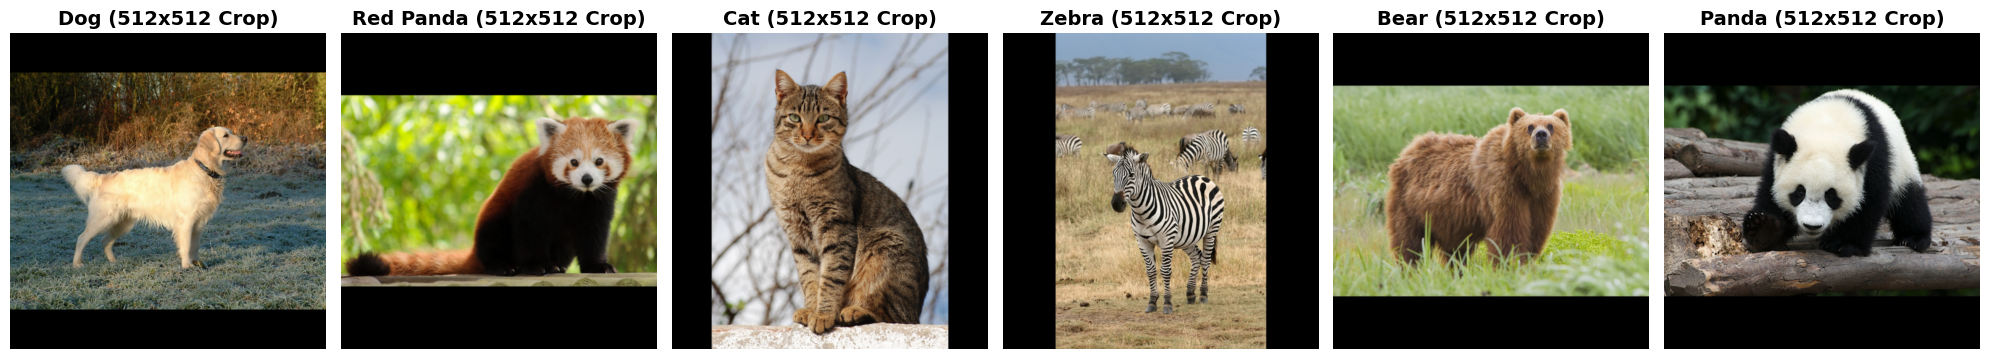

In [104]:
fig, axes = plt.subplots(1, 6, figsize=(20, 4))

for ax, (name, url) in zip(axes, animal_urls.items()):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()

        img_original = Image.open(BytesIO(response.content)).convert("RGB")
        animal_images_original[name] = img_original

        img_cropped = thesis_transform(img_original)
        animal_images_cropped[name] = img_cropped

        ax.imshow(img_cropped)
        ax.set_title(f"{name} (512x512 Crop)", fontsize=14, fontweight='bold')
        ax.axis("off")

        time.sleep(3)

    except Exception as e:
        print(f"❌ Failed to load {name}: {e}")

plt.tight_layout()
plt.show()

## **2. Patch Feature Extractions**


### **2.1 Ready up the model**

In [ ]:
model.to(device)
model.eval()

In [106]:
patch_features_dict = {}

### **2.2 Loop**

In [108]:
with torch.no_grad():
  for name, img, in animal_images_cropped.items():

    inputs = processor(images=img, return_tensors="pt", do_resize=False).to(device)
    output = model(**inputs)

    last_hidden_state = output.last_hidden_state

    patch_tokens = last_hidden_state[0, 1:, :]

    patch_features_dict[name] = patch_tokens.cpu().numpy()

print(f"\nExtracting Features, complete of size {len(patch_features_dict)}")


Extracting Features, complete of size 6


## **3. Data preparation**

### **3.1 Grouping data**

In [109]:
all_features = []
animal_labels = [] # To keep track of which animal a patch belongs to

In [110]:
for animal_name, features in patch_features_dict.items():
    all_features.append(features)
    animal_labels.extend([animal_name] * features.shape[0])

In [111]:
X = np.vstack(all_features)
animal_labels = np.array(animal_labels)

print(f"Total dataset shape for clustering: {X.shape}")

Total dataset shape for clustering: (6168, 4096)


## **4. K-Means**
We will be using default **K-Means++** from the `sklearn` library

### **4.1 Imports**

In [112]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

### **4.2 K-means with K of our choice**

In [122]:
num_clusters = 6

In [123]:
kmeans = KMeans(n_clusters=num_clusters, init='k-means++', random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X)

In [124]:
cross_user = pd.crosstab(pd.Series(cluster_labels, name='Cluster'), pd.Series(animal_labels, name='Animal'))

### **4.3 Elbow Method**

In [116]:
print("Calculating K-Means inertias for K=2 to K=15 (This may take a minute)...")
K_range = range(2, 16)
inertias = []

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X)
    inertias.append(km.inertia_)

p1 = np.array([K_range[0], inertias[0]])
p2 = np.array([K_range[-1], inertias[-1]])
distances = []

for i in range(len(K_range)):
    p3 = np.array([K_range[i], inertias[i]])
    dist = np.abs(np.cross(p2 - p1, p3 - p1)) / np.linalg.norm(p2 - p1)
    distances.append(dist)

optimal_k = K_range[np.argmax(distances)]
print(f"✅ Mathematically calculated Optimal K: {optimal_k}")

Calculating K-Means inertias for K=2 to K=15 (This may take a minute)...
✅ Mathematically calculated Optimal K: 6


/tmp/ipython-input-6693/4150210922.py:16: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  dist = np.abs(np.cross(p2 - p1, p3 - p1)) / np.linalg.norm(p2 - p1)


In [117]:
km_elbow = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
labels_elbow = km_elbow.fit_predict(X)

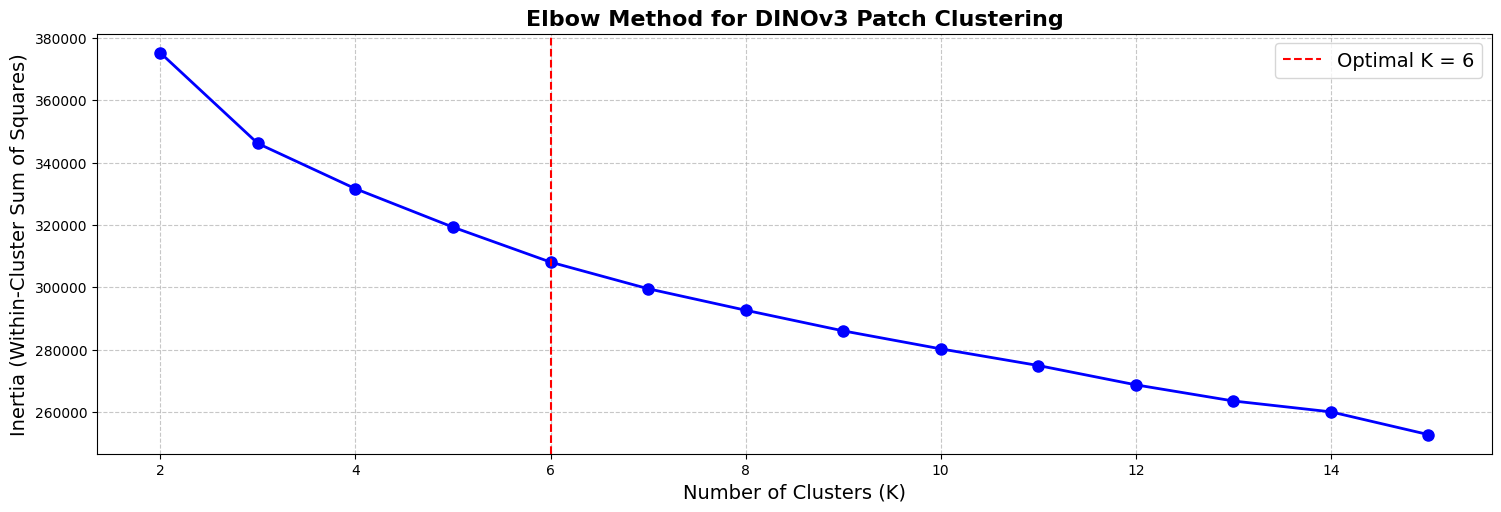

In [118]:
cross_elbow = pd.crosstab(pd.Series(labels_elbow, name='Cluster'), pd.Series(animal_labels, name='Animal'))
fig = plt.figure(figsize=(18, 12))

ax1 = plt.subplot(2, 1, 1)
ax1.plot(K_range, inertias, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
ax1.axvline(x=optimal_k, color='r', linestyle='--', label=f'Optimal K = {optimal_k}')
ax1.set_title("Elbow Method for DINOv3 Patch Clustering", fontsize=16, fontweight='bold')
ax1.set_xlabel("Number of Clusters (K)", fontsize=14)
ax1.set_ylabel("Inertia (Within-Cluster Sum of Squares)", fontsize=14)
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend(fontsize=14)

### **4.4 Histogram visualisation**

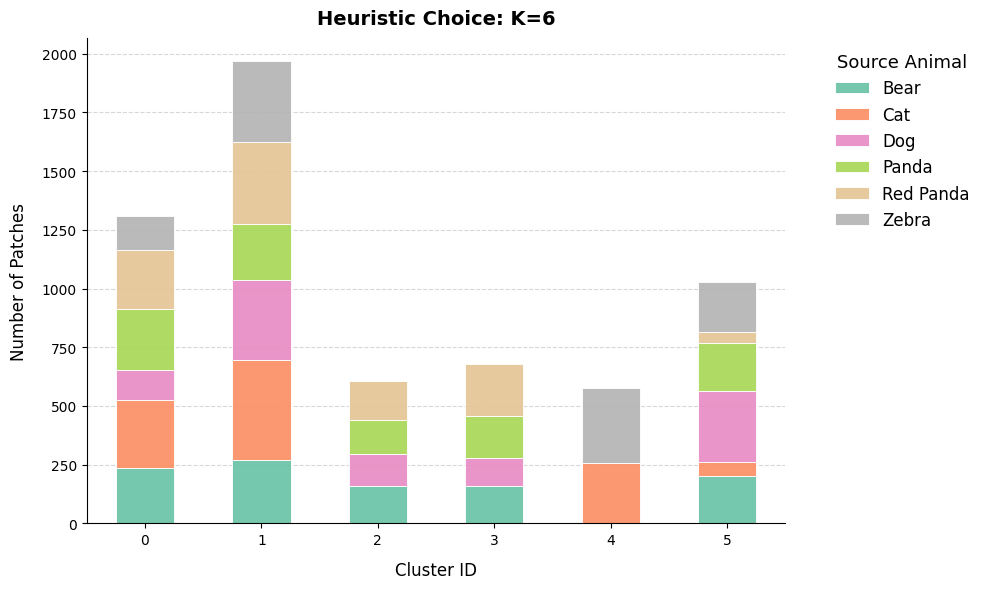

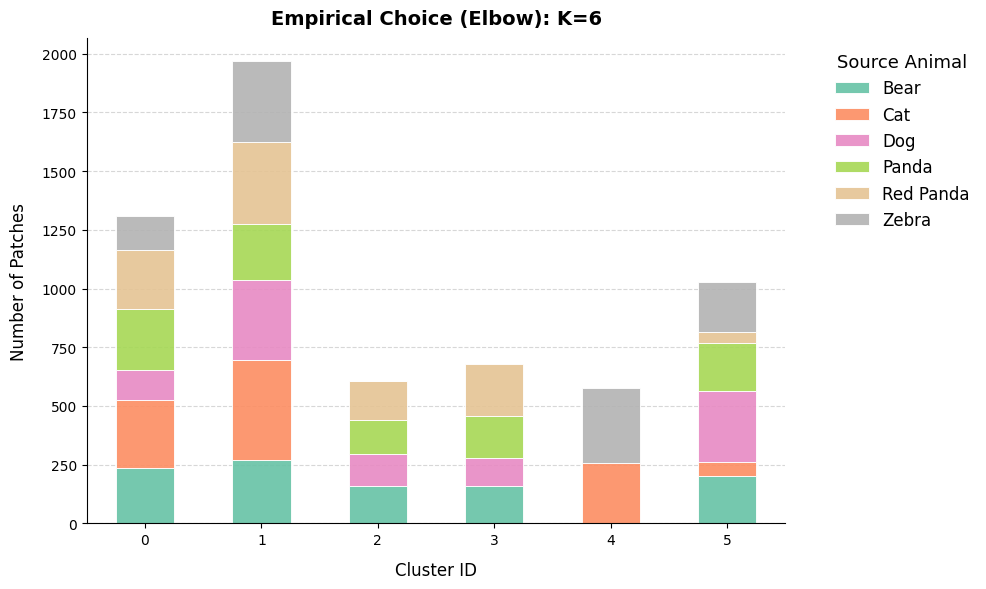

In [125]:
plot_cmap = 'Set2'

fig1, ax1 = plt.subplots(figsize=(10, 6))
cross_user.plot(kind='bar', stacked=True, ax=ax1, cmap=plot_cmap, edgecolor='white', linewidth=0.7, alpha=0.9)

ax1.set_title(f"Heuristic Choice: K={num_clusters}", fontsize=14, fontweight='bold', pad=10)
ax1.set_xlabel("Cluster ID", fontsize=12, labelpad=10)
ax1.set_ylabel("Number of Patches", fontsize=12, labelpad=10)
ax1.tick_params(axis='x', rotation=0)

ax1.set_axisbelow(True)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.spines[['top', 'right']].set_visible(False)

ax1.legend(title="Source Animal", title_fontsize='13', fontsize='12',
           loc='upper left', bbox_to_anchor=(1.05, 1), frameon=False)

plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(10, 6))
cross_elbow.plot(kind='bar', stacked=True, ax=ax2, cmap=plot_cmap, edgecolor='white', linewidth=0.7, alpha=0.9)

ax2.set_title(f"Empirical Choice (Elbow): K={optimal_k}", fontsize=14, fontweight='bold', pad=10)
ax2.set_xlabel("Cluster ID", fontsize=12, labelpad=10)
ax2.set_ylabel("Number of Patches", fontsize=12, labelpad=10)
ax2.tick_params(axis='x', rotation=0)

ax2.set_axisbelow(True)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.spines[['top', 'right']].set_visible(False)

ax2.legend(title="Source Animal", title_fontsize='13', fontsize='12',
           loc='upper left', bbox_to_anchor=(1.05, 1), frameon=False)

plt.tight_layout()
plt.show()

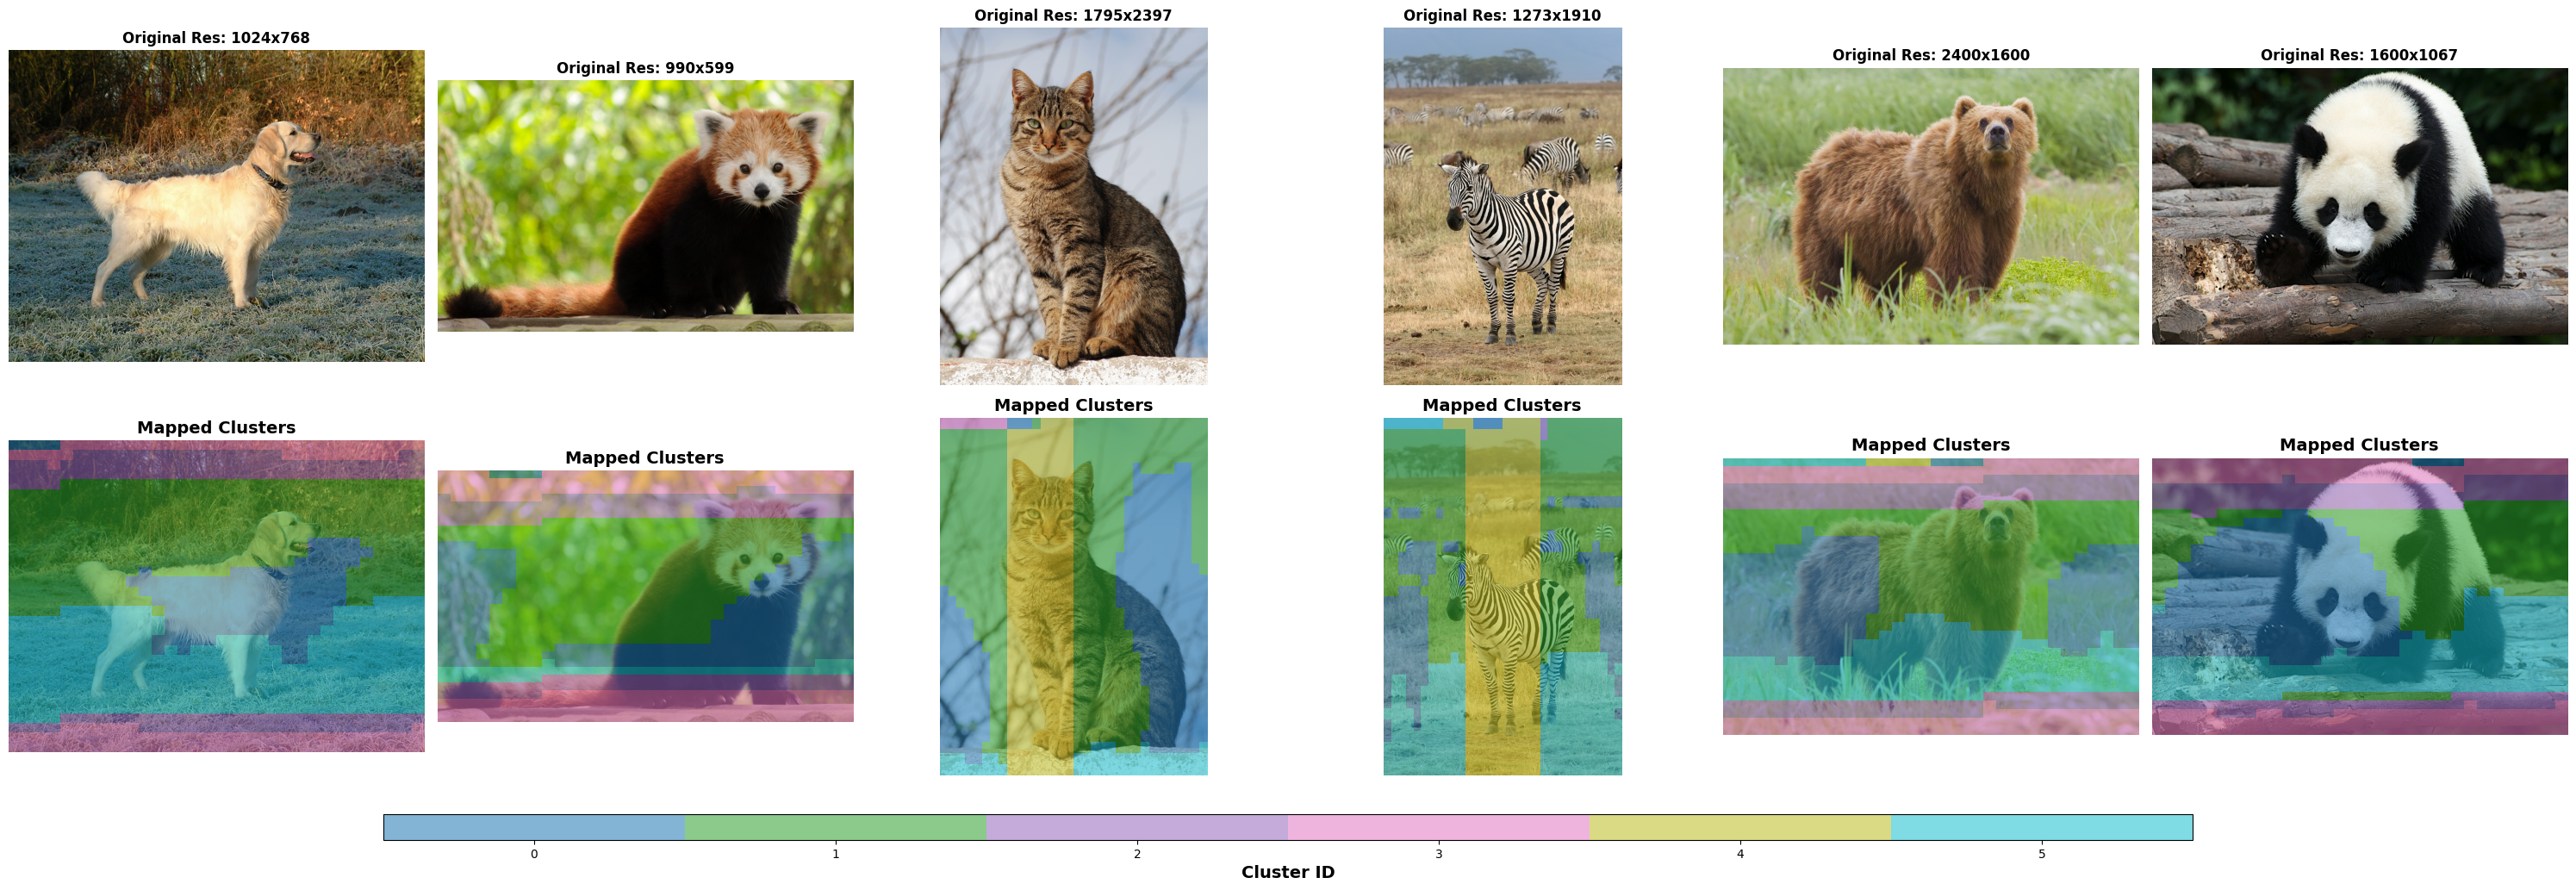

In [132]:
chosen_labels = cluster_labels
k = chosen_labels.max() + 1

discrete_cmap = plt.get_cmap('tab10', k)

patch_size = 16
grid_size = 512 // patch_size
num_images = len(animal_images_original)

fig, axes = plt.subplots(2, num_images, figsize=(5 * num_images, 10))
start_idx = 0

for i, (name, img_orig) in enumerate(animal_images_original.items()):

    orig_width, orig_height = img_orig.size

    end_idx = start_idx + (grid_size ** 2)
    img_labels_1d = chosen_labels[start_idx : end_idx]
    start_idx = end_idx

    cluster_grid_2d = img_labels_1d.reshape((grid_size, grid_size))

    axes[0, i].imshow(img_orig)
    axes[0, i].set_title(f"Original Res: {orig_width}x{orig_height}", fontsize=12, fontweight='bold')
    axes[0, i].axis('off')

    axes[1, i].imshow(img_orig)

    overlay = axes[1, i].imshow(
        cluster_grid_2d,
        cmap=discrete_cmap,
        alpha=0.55,
        extent=[0, orig_width, orig_height, 0],
        interpolation='nearest',
        vmin=-0.5,
        vmax=k - 0.5
    )

    axes[1, i].set_title(f"Mapped Clusters", fontsize=14, fontweight='bold')
    axes[1, i].axis('off')

plt.tight_layout(rect=[0, 0.08, 1, 1])

cbar_ax = fig.add_axes([0.15, 0.02, 0.7, 0.03])

tick_locations = range(k)
cbar = fig.colorbar(overlay, cax=cbar_ax, orientation='horizontal', ticks=tick_locations)
cbar.set_label('Cluster ID', fontsize=14, fontweight='bold')

plt.show()